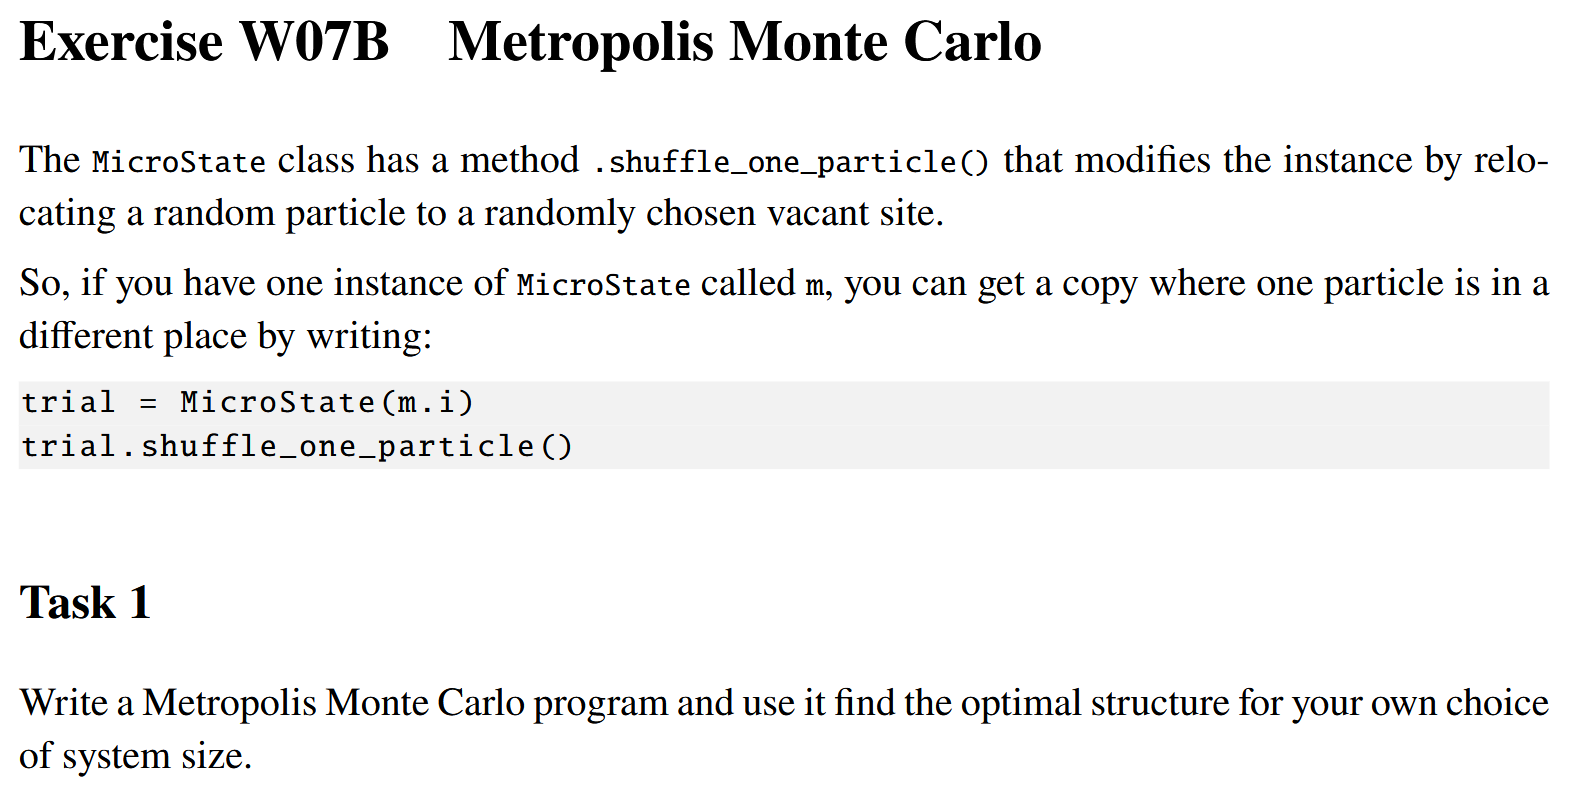

Optimal structure energy found: -3.25
Number of states with E=-3.25: 48


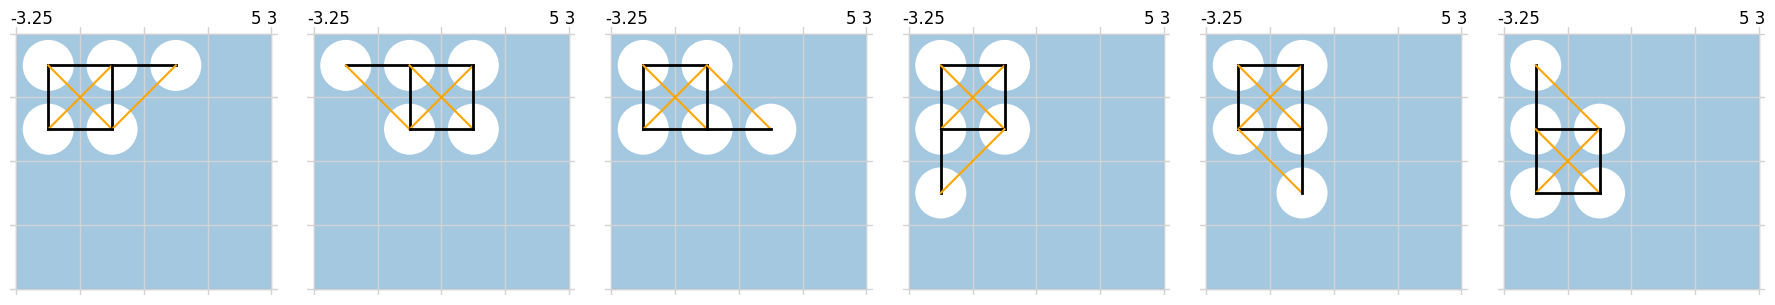

In [31]:
import numpy as np
import matplotlib.pyplot as plt 
from week07 import *

class TwoBinsDescriptor(DescriptorBase):

    centers = [1.0, 1.5]
    ylim = [0.0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, self.edges)
        return hist[0].tolist()

class MetropolisMonteCarlo:
    def __init__(self, factory, kT=0.15):
        self.factory = factory
        self.kT = kT

    def run(self, start_idx=0, steps=10_000):
        m = self.factory(start_idx)
        best_m = m
        destinct = {}

        for _ in range(steps):
            trial = self.factory(m.i)
            trial.shuffle_one_particle()

            de = trial.energy - m.energy

            if self.kT: cond = (de <= 0 or np.random.rand() <= np.exp(-de/self.kT))
            else: cond = (de <= 0)

            if cond:
                m = trial

            if m.energy < best_m.energy: 
                best_m = m

            desc_key = tuple(m.descriptor)
            if desc_key not in destinct:
                destinct[desc_key] = m

        self.best_m = best_m
        self.destinct = destinct

        return best_m, destinct

    def find_all_best(self):
        if not self.best_m:
            print('Simulation not run!')
            return
        
        # Find some states with the same descriptor to test uniqueness
        target_descriptor = self.best_m.descriptor
        matching_states = []

        # Search for matching states
        for i in range(self.factory.total): 
            if self.factory(i).descriptor == target_descriptor:
                matching_states.append(i)

        return matching_states

    def plot_best(self, num=4):
        if not self.best_m:
            print('Simulation not run!')
            return
        
        # Find some states with the same descriptor to test uniqueness
        target_descriptor = self.best_m.descriptor
        matching_states = []

        # Search for matching states
        i = 0
        while (len(matching_states) < num): 
            if self.factory(i).descriptor == target_descriptor:
                matching_states.append(i)
            i += 1

        fig, axes = plt.subplots(1, len(matching_states), figsize=(3 * len(matching_states), 3))
        for ax, idx in zip(axes, matching_states):
            MicroState(idx).plot(ax, label='Dual')
        plt.tight_layout()
        plt.show()
    
    def plot_distinct(self, num=4):
        if not self.destinct:
            print('Simulation not run!')
            return

        plots = min(num, len(self.destinct))
        fig, axes = plt.subplots(1, plots, figsize=(3*plots, 3))
        for ax, m in zip(np.atleast_1d(axes), list(visited.values())[:plots]):
            m.plot(ax, label='Dual')
        plt.suptitle("Distinct structures by Energy")
        plt.tight_layout()
        plt.show()
        return axes
            
    

descriptor = TwoBinsDescriptor()
MicroState = make_microstate_factory(N=5, L=4, descriptor_method=descriptor)

# Find optimal structure (using a higher kT to search effectively)
search = MetropolisMonteCarlo(factory=MicroState, kT=0.5)
best_state, visited = search.run()

print(f"Optimal structure energy found: {best_state.energy}")

all = search.find_all_best()
print(f'Number of states with E={best_state.energy}: {len(all)}')

search.plot_best(num=6)

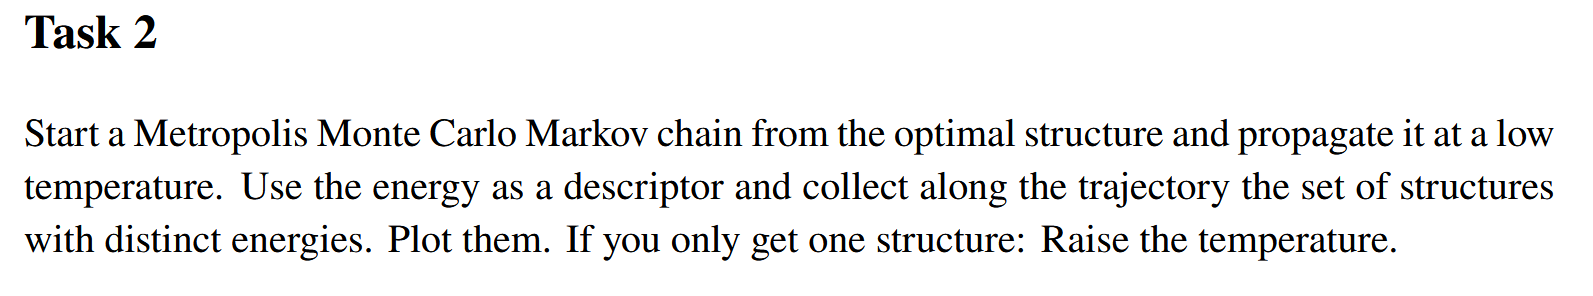

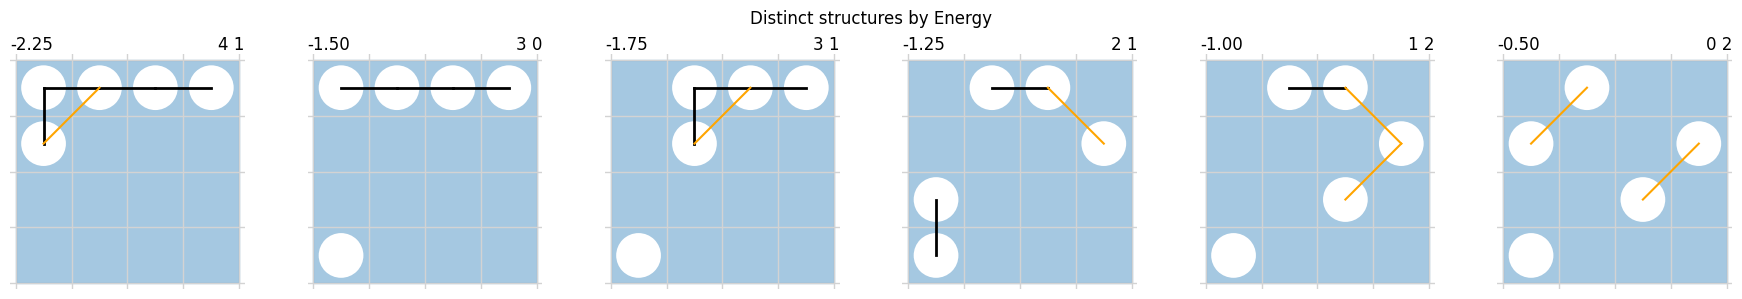

Number of destinct: 23


In [32]:
search.plot_distinct(num=6)
print(f'Number of destinct: {len(visited)}')

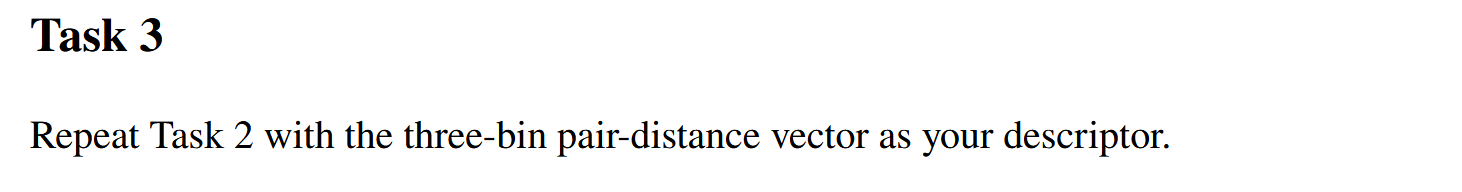

Optimal structure energy found: -6.75


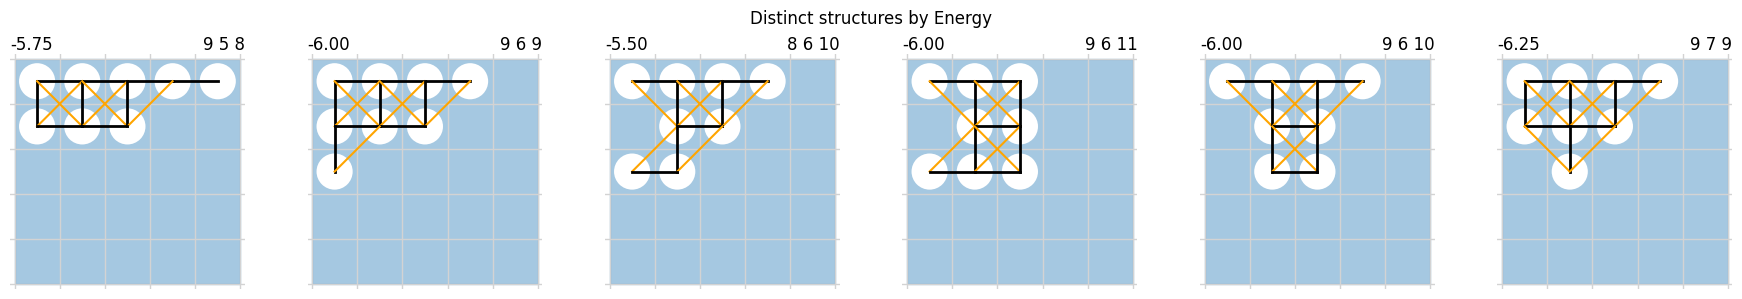

Number of destinct: 353


In [34]:
class ThreeBinsDescriptor(DescriptorBase):

    centers = [1.0, 1.5, 2.0]
    ylim = [0.0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, self.edges)
        return hist[0].tolist()

descriptor = ThreeBinsDescriptor()
MicroState = make_microstate_factory(N=8, L=5, descriptor_method=descriptor)

search = MetropolisMonteCarlo(factory=MicroState, kT=0.5)
best_state, visited = search.run()

print(f"Optimal structure energy found: {best_state.energy}")

search.plot_distinct(num=6)
print(f'Number of destinct: {len(visited)}')

Optimal structure energy found: -6.75


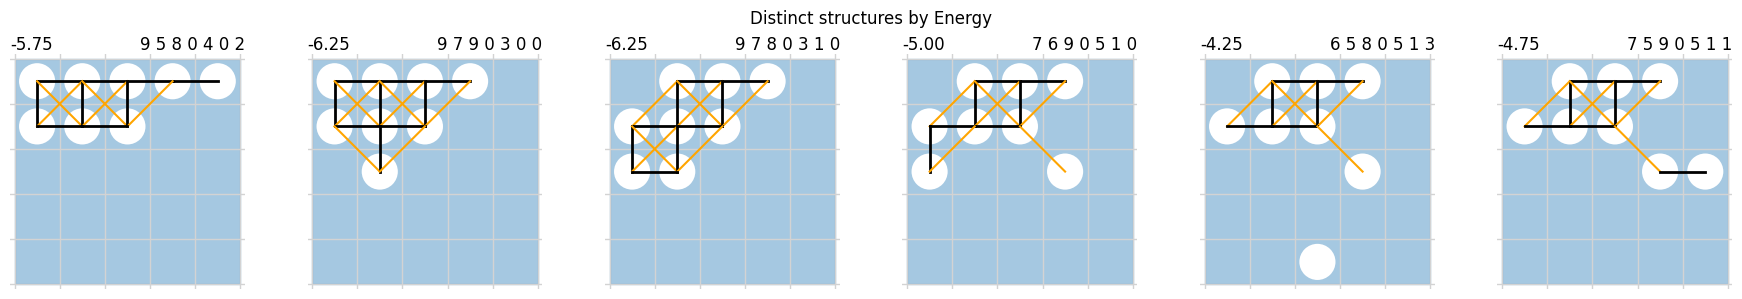

Number of destinct: 2081


In [35]:
class ManyBinsDescriptor(DescriptorBase):
    centers = np.arange(1.0, 4.5, 0.5)
    ylim = [0, 25]
    
    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, bins=self.edges)[0]
        return hist.tolist()

descriptor = ManyBinsDescriptor()
MicroState = make_microstate_factory(N=8, L=5, descriptor_method=descriptor)

search = MetropolisMonteCarlo(factory=MicroState, kT=0.5)
best_state, visited = search.run()

print(f"Optimal structure energy found: {best_state.energy}")

search.plot_distinct(num=6)
print(f'Number of destinct: {len(visited)}')